# Neo4j Social Network Analysis on Kaggle
A 2,000-user synthetic social network with planted communities and a few "celebrity" accounts, loaded into a **real Neo4j server running inside this notebook**.

**Before running:** start Neo4j with Docker (`docker compose up -d` in `notebooks/`). No GPU needed.

*Note: this notebook and `supply_chain_network.ipynb` share the same Neo4j database; each one only deletes its own nodes (`User` here, `Firm` there).*

Pipeline: generate data → load into Neo4j → Cypher analytics → NetworkX algorithms (PageRank, betweenness, Louvain) → write results back to Neo4j → visualize.

> Kaggle/Colab can't run Docker or the Neo4j GDS plugin, so graph algorithms run in NetworkX while Neo4j stores the graph and handles the queries.

## 1. Connect to Neo4j

*Java and Neo4j are not installed here: Neo4j runs in Docker (see `../docker-compose.yml`).*

In [1]:
import time
from neo4j import GraphDatabase

PW = "supplychain-pw"   # same Neo4j as in ../docker-compose.yml

driver = None
for _ in range(30):
    try:
        driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", PW))
        driver.verify_connectivity()
        break
    except Exception:
        time.sleep(2)
else:
    raise RuntimeError("Neo4j is not reachable: start it with docker compose up -d in notebooks/")
print("Neo4j is up")

def q(cypher, **params):
    with driver.session() as s:
        return s.run(cypher, **params).data()

Neo4j is up


## 2. Generate a larger network
8 planted communities (stochastic block model) plus 15 high-follower celebrity accounts.

*A test cell that used `nx` and `RR` before they were defined was removed (it failed when the notebook runs from top to bottom).*

In [2]:
import numpy as np, pandas as pd, networkx as nx, random
rng = np.random.default_rng(42); random.seed(42)

sizes = [300, 280, 260, 250, 240, 230, 220, 220]          # 2,000 users
K = len(sizes)
P = np.full((K, K), 0.0012); np.fill_diagonal(P, 0.03)    # dense inside, sparse between
SBM = nx.stochastic_block_model(sizes, P.tolist(), seed=42)

cities = ["Liège", "Brussels", "Paris", "Berlin", "Madrid", "Rome", "Vienna", "Lisbon"]
users = [{"id": i, "name": f"user_{i}", "city": cities[SBM.nodes[i]["block"]],
          "joined": int(rng.integers(2015, 2025)), "group": SBM.nodes[i]["block"]}
         for i in SBM.nodes]

edges = set()
for u, v in SBM.edges:
    a, b = (u, v) if rng.random() < 0.5 else (v, u)
    edges.add((a, b))
    if rng.random() < 0.35: edges.add((b, a))             # reciprocal follows

celebs = rng.choice(len(users), 15, replace=False)        # influencers
for c in celebs:
    for f in rng.choice(len(users), 150, replace=False):
        if f != c: edges.add((int(f), int(c)))

edge_rows = [{"s": int(a), "t": int(b)} for a, b in edges]
print(f"{len(users)} users, {len(edge_rows)} FOLLOWS edges")

2000 users, 15392 FOLLOWS edges


## 3. Load into Neo4j

In [3]:
def chunks(xs, n):
    for i in range(0, len(xs), n): yield xs[i:i+n]

q("MATCH (n:User) DETACH DELETE n")   # only the users: supply_chain_network.ipynb (Firm) can stay in the same database
q("CREATE CONSTRAINT user_id IF NOT EXISTS FOR (u:User) REQUIRE u.id IS UNIQUE")

for b in chunks(users, 1000):
    q("UNWIND $rows AS r MERGE (u:User {id: r.id}) SET u.name = r.name, u.city = r.city, u.joined = r.joined", rows=b)
for b in chunks(edge_rows, 2000):
    q("UNWIND $rows AS r MATCH (a:User {id: r.s}), (b:User {id: r.t}) MERGE (a)-[:FOLLOWS]->(b)", rows=b)

print(q("MATCH (u:User) RETURN count(u) AS users")[0],
      q("MATCH ()-[r:FOLLOWS]->() RETURN count(r) AS follows")[0])

{'users': 2000} {'follows': 15392}


## 4. Cypher analytics

In [4]:
# Most followed accounts
pd.DataFrame(q('''
MATCH (u:User)
RETURN u.id AS id, u.name AS name,
       COUNT { (u)<-[:FOLLOWS]-() } AS followers,
       COUNT { (u)-[:FOLLOWS]->() } AS following
ORDER BY followers DESC LIMIT 10'''))

,id,name,followers,following
0,1011,user_1011,161,6
1,475,user_475,160,15
2,1621,user_1621,157,7
3,1839,user_1839,156,8
4,576,user_576,156,6
5,1690,user_1690,156,7
6,1208,user_1208,156,2
7,1111,user_1111,156,18
8,1297,user_1297,155,6
9,397,user_397,154,4


In [5]:
# Reciprocity: share of follows that are mutual
r = q('''
MATCH (a:User)-[:FOLLOWS]->(b:User)
RETURN count(*) AS total,
       sum(CASE WHEN (b)-[:FOLLOWS]->(a) THEN 1 ELSE 0 END) AS mutual''')[0]
print(f"Reciprocity: {r['mutual']/r['total']:.1%}")

# Friend recommendations for user 0 (friends-of-friends not yet followed)
display(pd.DataFrame(q('''
MATCH (a:User {id: 0})-[:FOLLOWS]->(:User)-[:FOLLOWS]->(rec:User)
WHERE rec <> a AND NOT (a)-[:FOLLOWS]->(rec)
RETURN rec.name AS suggestion, rec.city AS city, count(*) AS mutual_connections
ORDER BY mutual_connections DESC LIMIT 10''')))

# Shortest path between two users in different communities
print(q('''
MATCH (a:User {id: 0}), (b:User {id: 1999})
MATCH p = shortestPath((a)-[:FOLLOWS*..8]-(b))
RETURN [n IN nodes(p) | n.name] AS path, length(p) AS hops'''))

Reciprocity: 44.8%


,suggestion,city,mutual_connections
0,user_285,Liège,2
1,user_157,Liège,1
2,user_290,Liège,1
3,user_120,Liège,1
4,user_1906,Lisbon,1
5,user_287,Liège,1
6,user_1461,Rome,1
7,user_1040,Berlin,1
8,user_493,Brussels,1
9,user_475,Brussels,1


[{'path': ['user_0', 'user_258', 'user_228', 'user_1056', 'user_1999'], 'hops': 4}]


## 5. Graph algorithms (NetworkX) and write-back to Neo4j

In [6]:
from sklearn.metrics import adjusted_rand_score

rows = q("MATCH (a:User)-[:FOLLOWS]->(b:User) RETURN a.id AS s, b.id AS t")
DG = nx.DiGraph([(r["s"], r["t"]) for r in rows])
UG = DG.to_undirected()

pagerank    = nx.pagerank(DG)
betweenness = nx.betweenness_centrality(UG, k=300, seed=42)   # sampled for speed
communities = nx.community.louvain_communities(UG, seed=42)
comm_of = {n: i for i, c in enumerate(communities) for n in c}

truth = [u["group"] for u in users]
found = [comm_of[u["id"]] for u in users]
print(f"Louvain found {len(communities)} communities; ARI vs planted groups = {adjusted_rand_score(truth, found):.3f}")

payload = [{"id": n, "pr": pagerank[n], "bt": betweenness[n], "c": comm_of[n]} for n in DG.nodes]
for b in chunks(payload, 1000):
    q("UNWIND $rows AS r MATCH (u:User {id: r.id}) SET u.pagerank = r.pr, u.betweenness = r.bt, u.community = r.c", rows=b)

Louvain found 6 communities; ARI vs planted groups = 0.747


In [7]:
# Query the enriched graph back out of Neo4j
display(pd.DataFrame(q('''
MATCH (u:User)
WITH u.community AS community, u ORDER BY u.pagerank DESC
RETURN community, count(*) AS members, collect(u.name)[0..3] AS top_by_pagerank
ORDER BY members DESC''')))

# Bridge users: most cross-community follows
display(pd.DataFrame(q('''
MATCH (a:User)-[:FOLLOWS]-(b:User) WHERE a.community <> b.community
RETURN a.name AS user, a.community AS community, count(*) AS cross_links
ORDER BY cross_links DESC LIMIT 10''')))

,community,members,top_by_pagerank
0,0,532,"[user_1297, user_493, user_1180]"
1,5,452,"[user_1549, user_576, user_397]"
2,3,283,"[user_475, user_371, user_527]"
3,1,261,"[user_1597, user_838, user_663]"
4,2,249,"[user_1208, user_1011, user_874]"
5,4,223,"[user_1690, user_1621, user_1684]"


,user,community,cross_links
0,user_1690,4,136
1,user_1597,1,135
2,user_1208,2,134
3,user_1111,5,133
4,user_475,3,133
5,user_1684,4,132
6,user_1011,2,130
7,user_1621,4,130
8,user_576,5,121
9,user_1056,5,118


## 6. Visualize

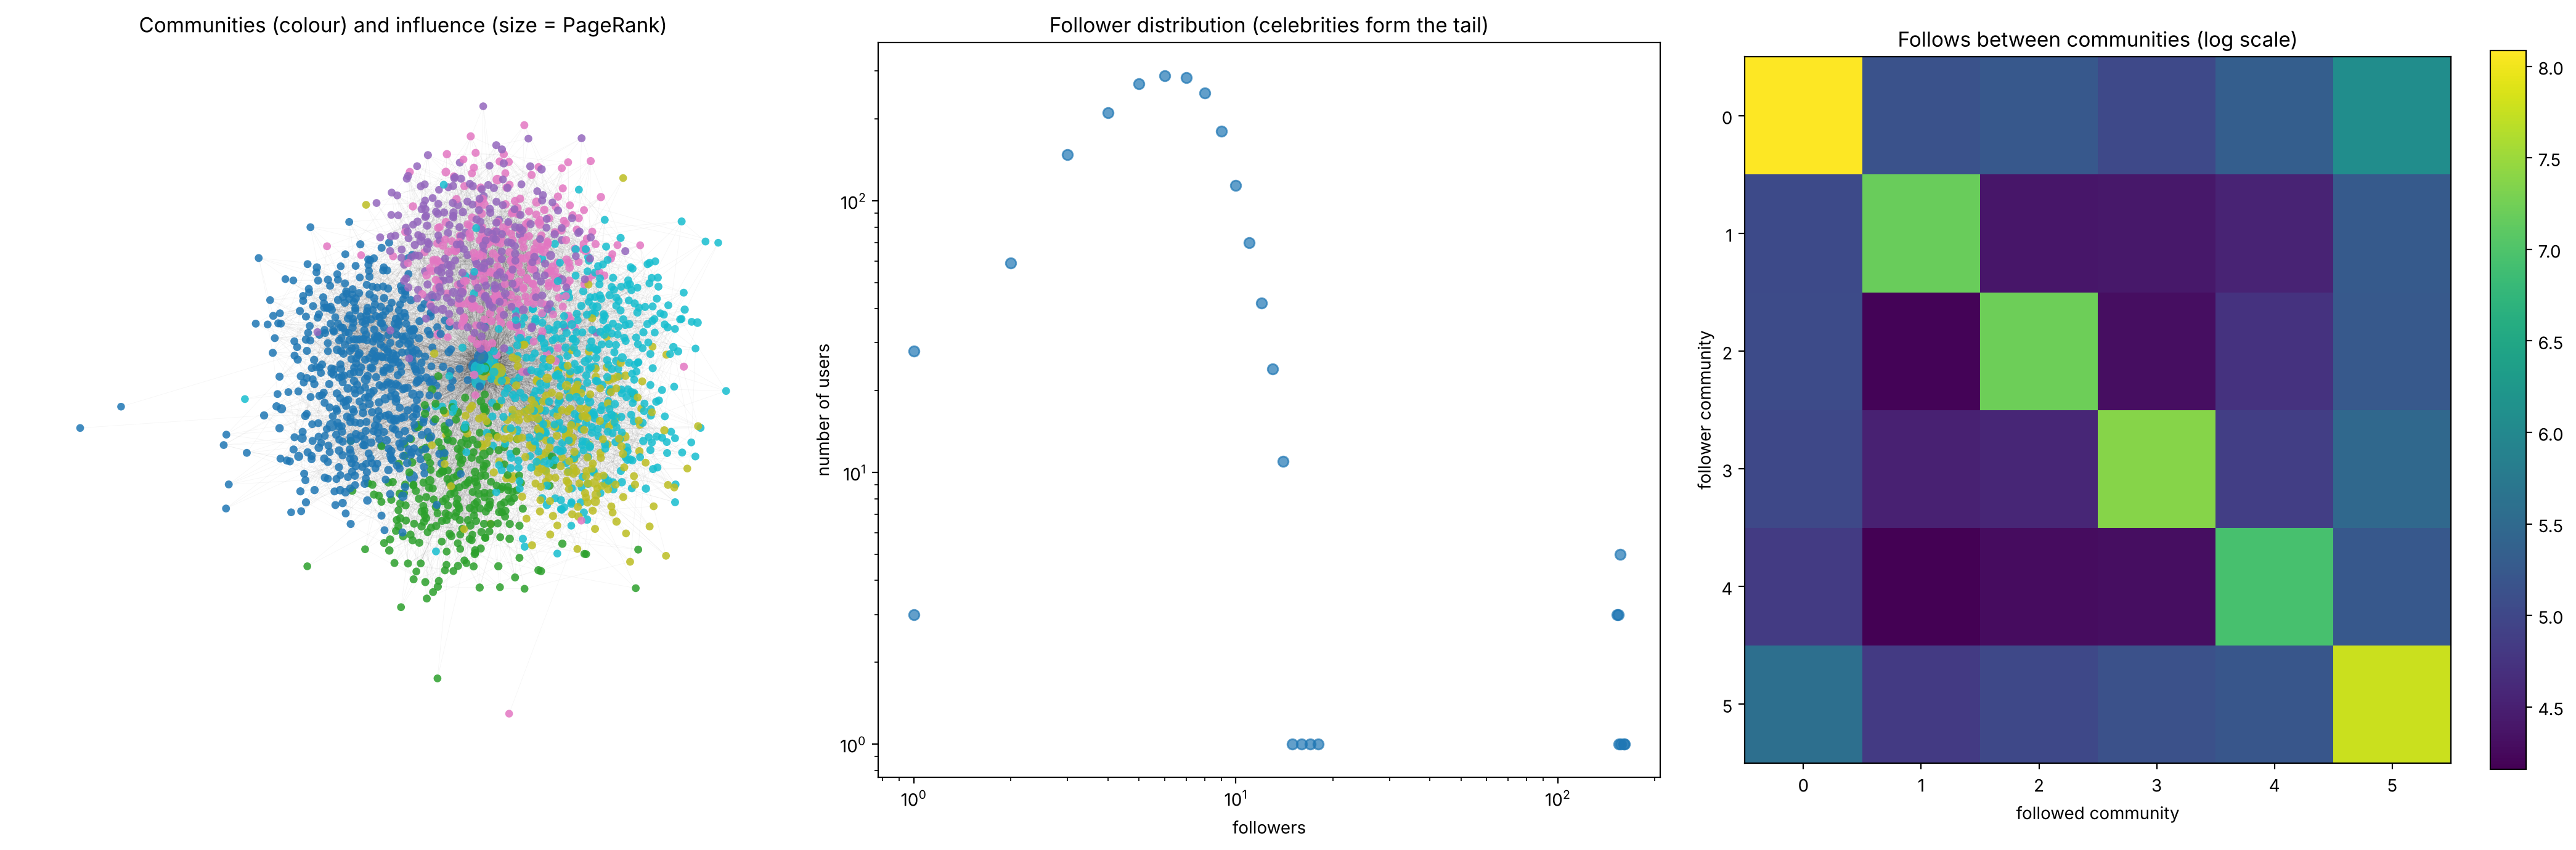

In [8]:
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# (a) Whole network: colour = community, size = PageRank
pos = nx.spring_layout(UG, k=0.12, iterations=60, seed=42)
nodes = list(UG.nodes)
colors = [comm_of[n] for n in nodes]
sizes_ = [20 + 6000 * pagerank[n] for n in nodes]
nx.draw_networkx_edges(UG, pos, ax=axes[0], alpha=0.04, width=0.3)
axes[0].scatter([pos[n][0] for n in nodes], [pos[n][1] for n in nodes],
                c=colors, s=sizes_, cmap="tab10", alpha=0.85, linewidths=0)
axes[0].set_title("Communities (colour) and influence (size = PageRank)"); axes[0].axis("off")

# (b) Follower distribution (log-log)
indeg = pd.Series(dict(DG.in_degree())).value_counts().sort_index()
# Fix: Convert the index to a series before clipping, or use np.clip
axes[1].loglog(pd.Series(indeg.index).clip(lower=1), indeg.values, "o", alpha=0.7)
axes[1].set_xlabel("followers"); axes[1].set_ylabel("number of users")
axes[1].set_title("Follower distribution (celebrities form the tail)")

# (c) Community-to-community follow matrix
n_c = len(communities); M = np.zeros((n_c, n_c))
for a, b in DG.edges: M[comm_of[a], comm_of[b]] += 1
im = axes[2].imshow(np.log1p(M), cmap="viridis")
axes[2].set_title("Follows between communities (log scale)")
axes[2].set_xlabel("followed community"); axes[2].set_ylabel("follower community")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

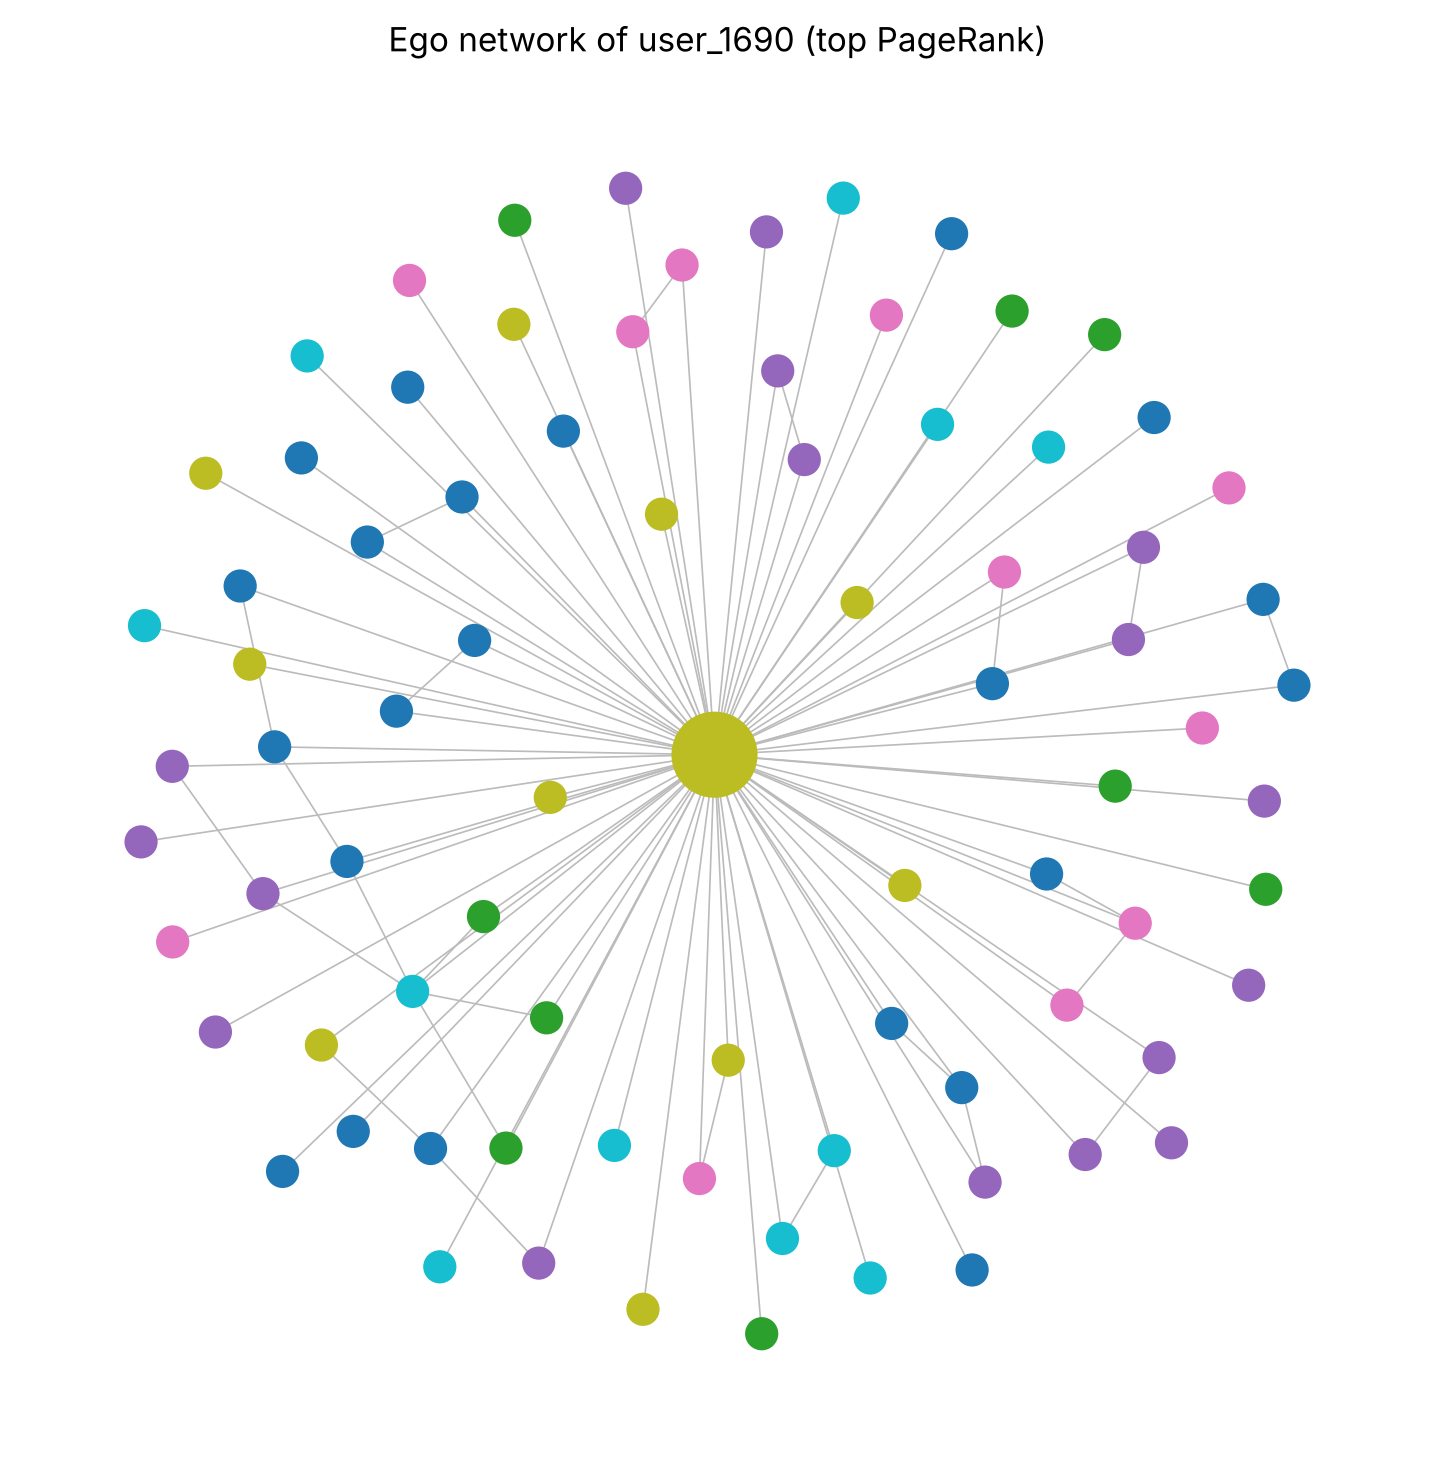

In [9]:
# Ego network of the most influential user
top = max(pagerank, key=pagerank.get)
nbrs = list(UG.neighbors(top)); random.seed(1)
sample = random.sample(nbrs, min(80, len(nbrs)))
E = UG.subgraph([top] + sample)
plt.figure(figsize=(9, 9))
p2 = nx.spring_layout(E, seed=3)
nx.draw_networkx(E, p2, node_color=[comm_of[n] for n in E], cmap="tab10",
                 node_size=[900 if n == top else 120 for n in E],
                 with_labels=False, edge_color="#bbbbbb", width=0.6)
plt.title(f"Ego network of user_{top} (top PageRank)"); plt.axis("off")
plt.show()

## 7. Shut down

In [10]:
driver.close()
print("connection closed (stop Neo4j with: docker compose down)")

connection closed (stop Neo4j with: docker compose down)
